In [15]:
from pathlib import Path
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import seaborn as sns

import ipywidgets as widgets
from IPython.display import display

import torch
# from segment_anything import sam_model_registry, SamAutomaticMaskGenerator

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Device
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")

# Project paths
PROJECT_ROOT = Path.cwd().parent  # If notebook is in notebooks/
DATA_DIR = PROJECT_ROOT / "data"
MODEL_PATH = PROJECT_ROOT / "models" / "sam_vit_b_01ec64.pth"

Using device: cpu


Preprocessing the metadata and ground truth

In [ ]:
# image_paths = list(DATA_DIR.rglob("*.jpg"))
df_milk_truth = pd.read_csv(DATA_DIR / "MILK10k_Training_GroundTruth.csv")
df_milk_meta = pd.read_csv(DATA_DIR / "MILK10k_Training_Metadata.csv")

df_milk = df_milk_meta.merge(df_milk_truth, on="lesion_id", how="left", validate="many_to_one")

df_milk["path"] = df_milk.apply(lambda row: Path("MILK10k_Training_Input") / row["lesion_id"] / f"{row['isic_id']}.jpg", axis=1)

Check data

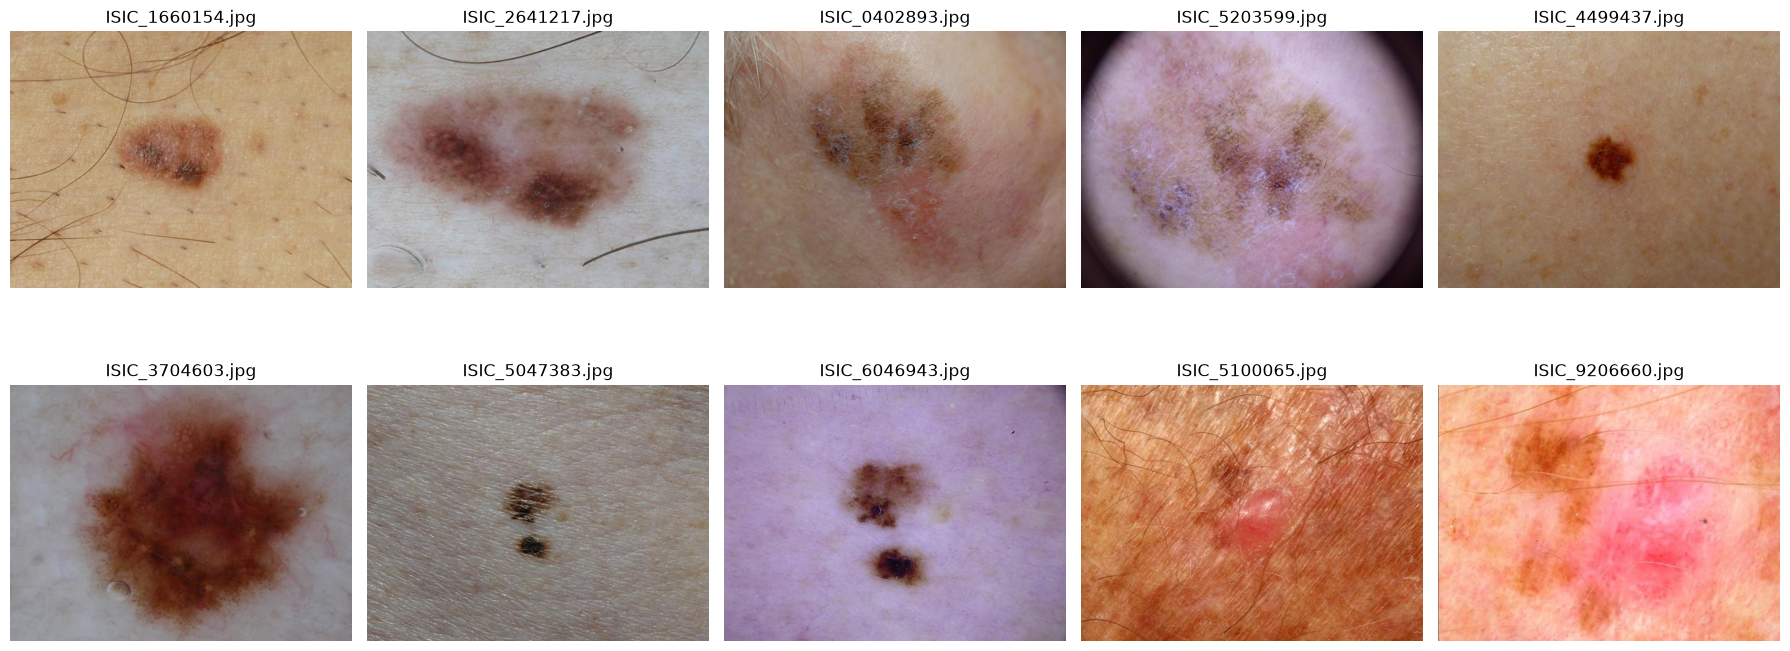

In [ ]:
diagnoses = ["AKIEC", "BCC", "BEN_OTH", "BKL", "DF", "INF", "MAL_OTH", "MEL", "NV", "SCCKA", "VASC"]


def load_image(path):
    image = Image.open(path).convert("RGB")
    return np.array(image)


fig, axes = plt.subplots(2, 5, figsize=(18, 8))

for ax, path in zip(axes.flat, df_milk[df_milk["MEL"] == 1].path):
    image = load_image(DATA_DIR / path)

    ax.imshow(image)
    ax.set_title(path.name)
    ax.axis("off")

plt.tight_layout()
plt.show()


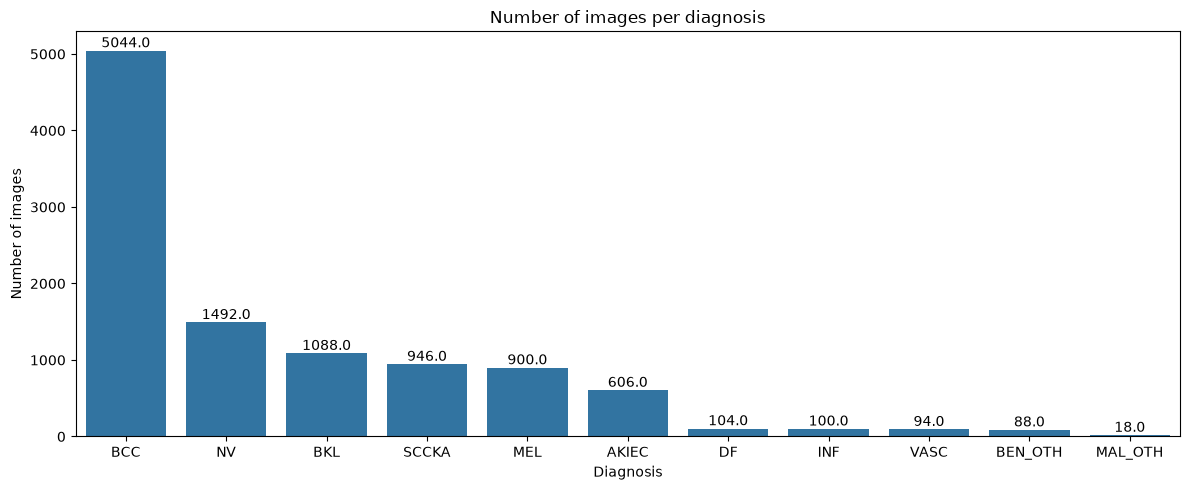

In [ ]:
diagnoses = ["AKIEC", "BCC", "BEN_OTH", "BKL", "DF", "INF", "MAL_OTH", "MEL", "NV", "SCCKA", "VASC"]

counts = df_milk[diagnoses].sum().sort_values(ascending=False)

plt.figure(figsize=(12, 5))
sns.barplot(x=counts.index, y=counts.values)

plt.xlabel("Diagnosis")
plt.ylabel("Number of images")
plt.title("Number of images per diagnosis")

for i, count in enumerate(counts.values):
    plt.text(i, count, str(count), ha="center", va="bottom")

plt.tight_layout()
plt.show()

Use ISIC-2017 data because they come with segmentation masks

In [ ]:
df_isic_truth = pd.read_csv(DATA_DIR / "ISIC-2017_Training_Part3_GroundTruth.csv")
df_isic_meta = pd.read_csv(DATA_DIR / "ISIC-2017_Training_Data/ISIC-2017_Training_Data_metadata.csv")

df_isic = df_isic_meta.merge(df_isic_truth, on="image_id", how="left", validate="many_to_one")

df_isic["path"] = df_isic.apply(lambda row: Path("ISIC-2017_Training_resizedImages") / f"{row['image_id']}.jpg", axis=1)
df_isic["path_segmentation"] = df_isic.apply(
    lambda row: Path("ISIC-2017_Training_resizedSegmentation") / f"{row['image_id']}_segmentation.png", axis=1
)

df_isic = df_isic.rename(columns={"melanoma": "MEL"})
df_isic["NV"] = ((df_isic["MEL"] == 0) & (df_isic["seborrheic_keratosis"] == 0)).astype(float)

df_milk

,lesion_id,image_type,isic_id,attribution,copyright_license,image_manipulation,age_approx,sex,skin_tone_class,site,...,BEN_OTH,BKL,DF,INF,MAL_OTH,MEL,NV,SCCKA,VASC,path
0,IL_0000652,clinical: close-up,ISIC_8149219,MILK study team,CC-BY-NC,altered,70.0,male,1,head_neck_face,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,MILK10k_Training_Input\IL_0000652\ISIC_8149219...
1,IL_0000652,dermoscopic,ISIC_4671410,MILK study team,CC-BY-NC,instrument only,70.0,male,1,head_neck_face,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,MILK10k_Training_Input\IL_0000652\ISIC_4671410...
2,IL_0003176,clinical: close-up,ISIC_3904045,MILK study team,CC-BY-NC,instrument only,45.0,female,5,head_neck_face,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,MILK10k_Training_Input\IL_0003176\ISIC_3904045...
3,IL_0003176,dermoscopic,ISIC_5371928,MILK study team,CC-BY-NC,instrument only,45.0,female,5,head_neck_face,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,MILK10k_Training_Input\IL_0003176\ISIC_5371928...
4,IL_0004688,clinical: close-up,ISIC_0791494,MILK study team,CC-BY-NC,instrument only,50.0,male,3,lower_extremity,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,MILK10k_Training_Input\IL_0004688\ISIC_0791494...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10475,IL_9994739,dermoscopic,ISIC_4873822,MILK study team,CC-BY-NC,instrument only,85.0,male,3,upper_extremity,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,MILK10k_Training_Input\IL_9994739\ISIC_4873822...
10476,IL_9995614,clinical: close-up,ISIC_9832572,MILK study team,CC-BY-NC,instrument only,55.0,male,4,trunk,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,MILK10k_Training_Input\IL_9995614\ISIC_9832572...
10477,IL_9995614,dermoscopic,ISIC_7749901,MILK study team,CC-BY-NC,instrument only,55.0,male,4,trunk,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,MILK10k_Training_Input\IL_9995614\ISIC_7749901...
10478,IL_9998211,clinical: close-up,ISIC_1830925,MILK study team,CC-BY-NC,instrument only,70.0,male,2,trunk,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,MILK10k_Training_Input\IL_9998211\ISIC_1830925...


In [30]:
df_isic.columns

Index(['image_id', 'age_approximate', 'sex', 'MEL', 'seborrheic_keratosis',
       'path', 'path_segmentation', 'NV'],
      dtype='str')

In [ ]:
fig, axes = plt.subplots(2, 5, figsize=(18, 8))

for ax, path in zip(axes.flat, df_milk[df_milk["MEL"] == 1].path):
    image = load_image(DATA_DIR / path)

    ax.imshow(image)
    ax.set_title(path.name)
    ax.axis("off")

plt.tight_layout()
plt.show()